# Temporal model performance

Evaluate the saved admission-level predictions by calendar period. The notebook contains orchestration only; reusable evaluation logic lives in `icare_risk.evaluation.temporal`.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import sys
import yaml
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

CONFIG_PATH = Path('../../src/icare_risk/config/icare/analysis.yaml')
with CONFIG_PATH.open() as f:
    config = yaml.safe_load(f)

from icare_risk.data.audit import load_admission_file

from icare_risk.evaluation.temporal import (
    evaluate_over_time,
    temporal_event_rate_summary,
    temporal_split_summary,
)

from icare_risk.evaluation.plots import (
    plot_temporal_metrics,
    plot_calibration_metrics,
    plot_threshold_metrics,
    plot_temporal_event_rate,
    save_figure,
)


In [3]:
prediction_directory = Path(config['outputs']['prediction_directory'])
prediction_path = prediction_directory / 'admission_predictions.parquet'
if not prediction_path.exists():
    csv_path = prediction_directory / 'admission_predictions.csv'
    prediction_path = csv_path if csv_path.exists() else prediction_path

predictions = load_admission_file(prediction_path)
columns = config['columns']
date_column = columns['admission_date']
target_column = columns['target']
split_column = 'split'
target_mapping = config.get('target_mapping', config.get('analysis', {}).get('target_mapping', {}))
freq = config.get('analysis', {}).get('temporal_frequency', 'Q')
threshold = config.get('analysis', {}).get('evaluation_threshold', 0.5)
prediction_columns = [c for c in predictions.columns if c.endswith('_prob')]

required = [date_column, target_column, *prediction_columns]
missing = [c for c in required if c not in predictions.columns]
if missing:
    raise KeyError(f'Missing required prediction-table columns: {missing}')

range_min = pd.to_datetime(predictions[date_column], errors="coerce").min()
range_max = pd.to_datetime(predictions[date_column], errors="coerce").max()

print(f'Loaded {len(predictions):,} admissions from {prediction_path}')
print(f'Date range: {range_min} to {range_max}')
print(f'Temporal frequency: {freq}; fixed threshold: {threshold}')
print(f'Model probability columns: {len(prediction_columns)}')


Loaded 10,000 admissions from results/predictions/admission_predictions.parquet
Date range: 2020-01-01 00:00:00 to 2024-01-01 00:00:00
Temporal frequency: YS; fixed threshold: 0.5
Model probability columns: 6


## Event rate over calendar time

The event-rate line is aggregated across the whole cohort, ignoring `split` when grouping. This gives one point per calendar period, even when a year contains only part of the training, validation, or test interval.

The shaded regions and dashed lines show the configured split boundaries. They are visual annotations only; they do not alter the event-rate calculation.

,period,n_rows,n_resolved,n_events,n_non_events,event_rate
0,2020-01-01,2497,2497,480,2017,0.192231
1,2021-01-01,2521,2521,494,2027,0.195954
2,2022-01-01,2505,2505,513,1992,0.204790
3,2023-01-01,2472,2472,503,1969,0.203479
4,2024-01-01,5,5,2,3,0.400000


,split,period,n_rows,n_resolved,n_events,n_non_events,event_rate
0,test,2022,6,6,2.0,4.0,0.333333
1,test,2023,2472,2472,503.0,1969.0,0.203479
2,test,2024,5,5,2.0,3.0,0.400000
3,train,2020,2497,2497,480.0,2017.0,0.192231
4,train,2021,2521,2521,494.0,2027.0,0.195954
5,train,2022,1036,1036,204.0,832.0,0.196911
6,validation,2022,1463,1463,307.0,1156.0,0.209843


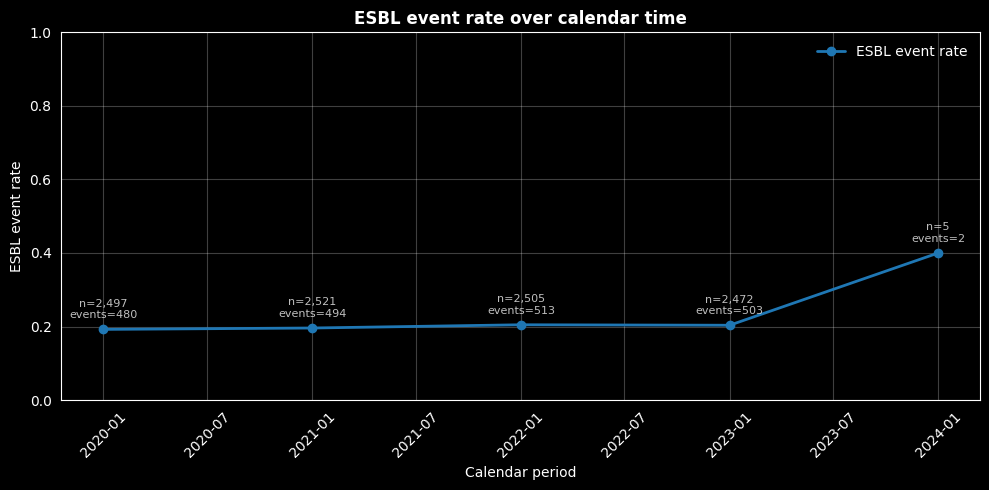

In [5]:
event_rate_summary = temporal_event_rate_summary(
    predictions,
    date_column=date_column,
    target_column=target_column,
    freq=freq,
    target_mapping=target_mapping,
)
split_summary = temporal_split_summary(
    predictions,
    date_column=date_column,
    target_column=target_column,
    split_column=split_column,
    freq=freq,
    target_mapping=target_mapping,
)
display(event_rate_summary)
display(split_summary.head(30))

split_boundaries = {
    'train_end': config['analysis']['train_end'],
    'validation_end': config['analysis']['validation_end'],
}
event_rate_figure = plot_temporal_event_rate(
    event_rate_summary,
    admissions_column='n_resolved',
    #split_boundaries=split_boundaries,
    title='ESBL event rate over calendar time',
)

## Model performance over time

Performance is evaluated only in the temporal test set. The same fixed threshold is applied in every period; thresholds are not re-optimised within individual calendar periods.

In [6]:
# Evaluate performance over time on the temporal test set.
evaluation_data = predictions.loc[predictions[split_column].eq('test')].copy()
print(f'Temporal test rows: {len(evaluation_data):,}')
temporal_results = evaluate_over_time(
    evaluation_data,
    date_column=date_column,
    target_column=target_column,
    prediction_columns=prediction_columns,
    freq=freq,
    threshold=threshold,
    target_mapping=target_mapping,
)
display(temporal_results)

Temporal test rows: 2,483


,period,period_label,model,prediction_column,n,n_events,event_rate,auroc,auprc,brier_score,...,tn,fp,fn,sensitivity,specificity,ppv,npv,accuracy,balanced_accuracy,f1
0,2022-01-01,2022-01-01,lr_kim_components,lr_kim_components_prob,6,2,0.333333,0.625000,0.400000,0.245267,...,1,3,0,1.000000,0.250000,0.400000,1.000000,0.500000,0.625000,0.571429
1,2022-01-01,2022-01-01,lr_all_score_values,lr_all_score_values_prob,6,2,0.333333,1.000000,1.000000,0.239035,...,1,3,0,1.000000,0.250000,0.400000,1.000000,0.500000,0.625000,0.571429
2,2022-01-01,2022-01-01,lr_clinical_baseline,lr_clinical_baseline_prob,6,2,0.333333,0.500000,0.416667,0.253761,...,2,2,2,0.000000,0.500000,0.000000,0.500000,0.333333,0.250000,0.000000
3,2022-01-01,2022-01-01,xgb_kim_components,xgb_kim_components_prob,6,2,0.333333,0.625000,0.400000,0.238615,...,4,0,2,0.000000,1.000000,0.000000,0.666667,0.666667,0.500000,0.000000
4,2022-01-01,2022-01-01,xgb_all_score_values,xgb_all_score_values_prob,6,2,0.333333,1.000000,1.000000,0.233238,...,4,0,2,0.000000,1.000000,0.000000,0.666667,0.666667,0.500000,0.000000
5,2022-01-01,2022-01-01,xgb_clinical_baseline,xgb_clinical_baseline_prob,6,2,0.333333,0.125000,0.291667,0.264822,...,4,0,2,0.000000,1.000000,0.000000,0.666667,0.666667,0.500000,0.000000
6,2023-01-01,2023-01-01,lr_kim_components,lr_kim_components_prob,2472,503,0.203479,0.503657,0.204622,0.249835,...,225,1744,54,0.892644,0.114271,0.204742,0.806452,0.272654,0.503458,0.333086
7,2023-01-01,2023-01-01,lr_all_score_values,lr_all_score_values_prob,2472,503,0.203479,0.507782,0.207372,0.249871,...,231,1738,54,0.892644,0.117318,0.205304,0.810526,0.275081,0.504981,0.333829
8,2023-01-01,2023-01-01,lr_clinical_baseline,lr_clinical_baseline_prob,2472,503,0.203479,0.507078,0.209463,0.255706,...,905,1064,232,0.538767,0.459624,0.202996,0.795954,0.475728,0.499196,0.294886
9,2023-01-01,2023-01-01,xgb_kim_components,xgb_kim_components_prob,2472,503,0.203479,0.503657,0.204622,0.162094,...,1969,0,503,0.000000,1.000000,0.000000,0.796521,0.796521,0.500000,0.000000


## Figures for temporal model performance

Small multiples are used rather than placing unrelated metrics on one axis. Discrimination, threshold performance, and calibration have different interpretations and are easier to read as separate panels.

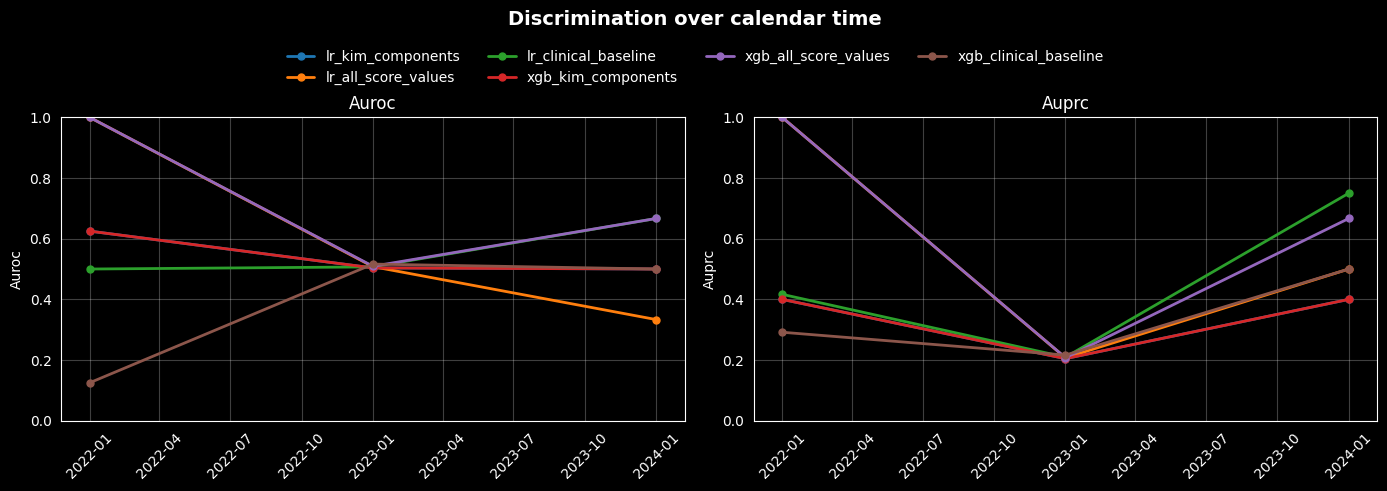

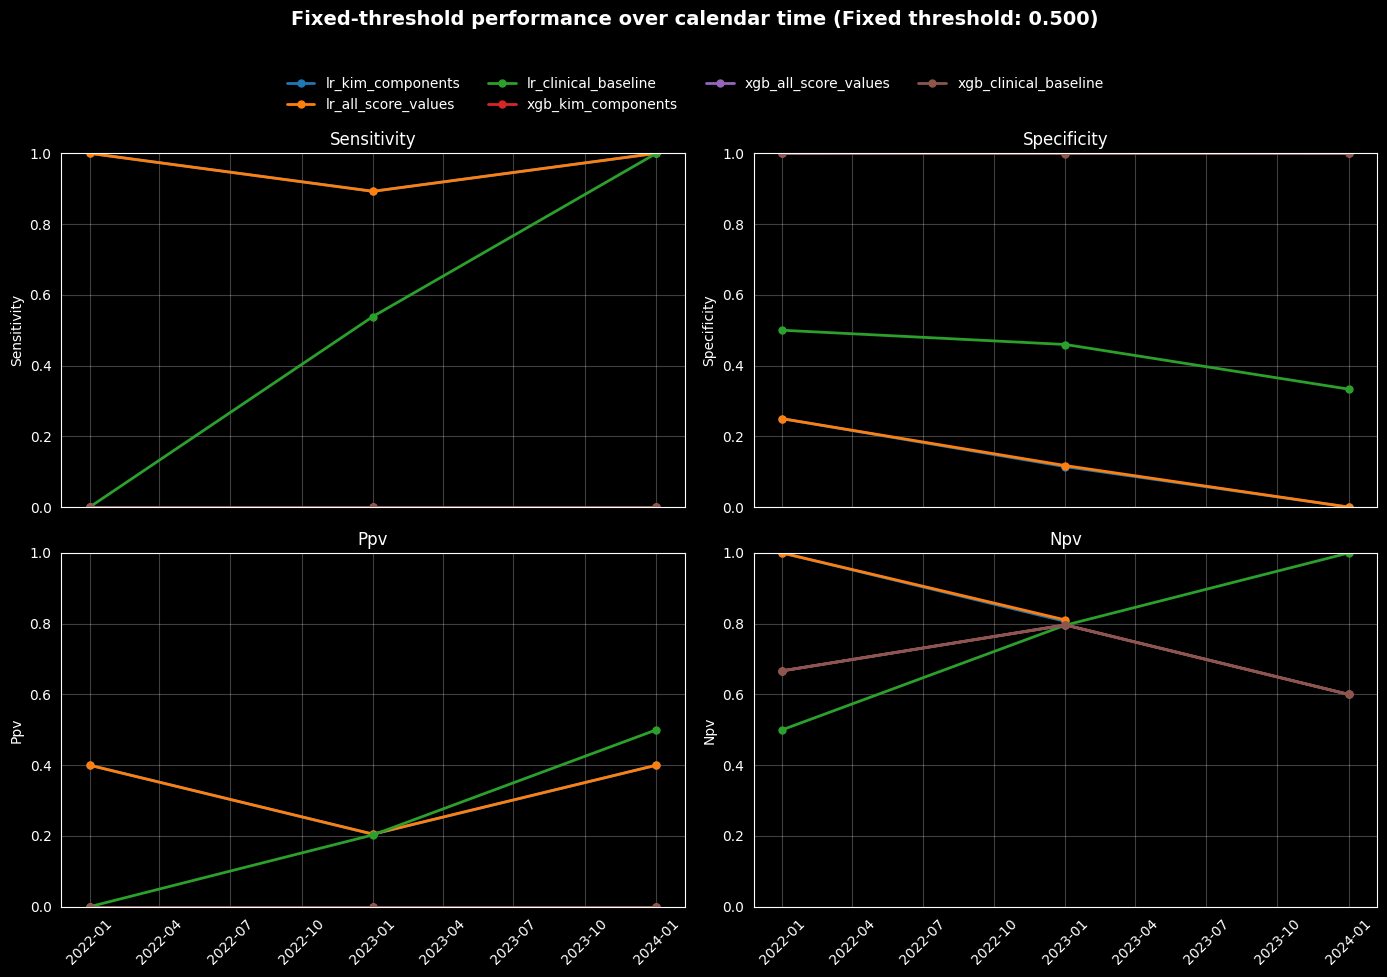

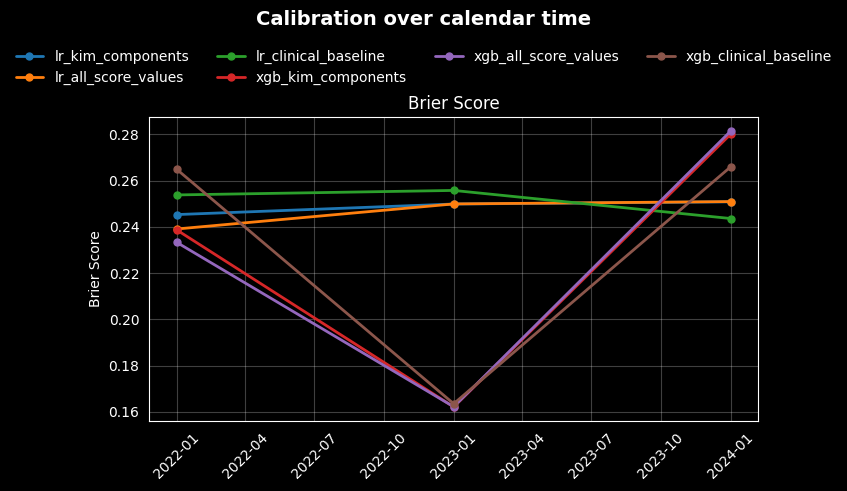

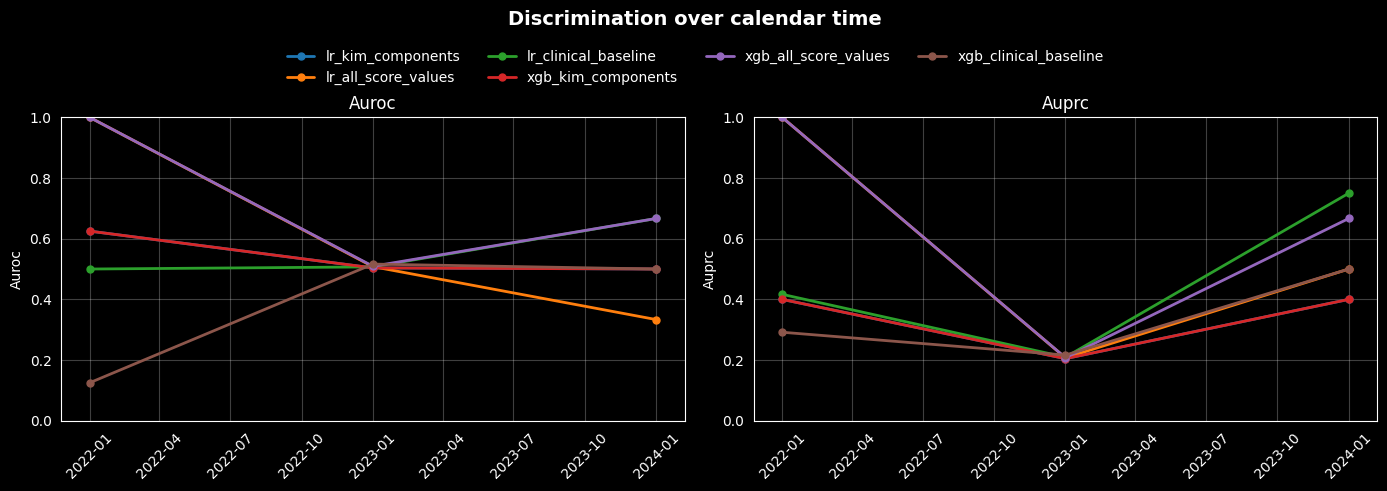

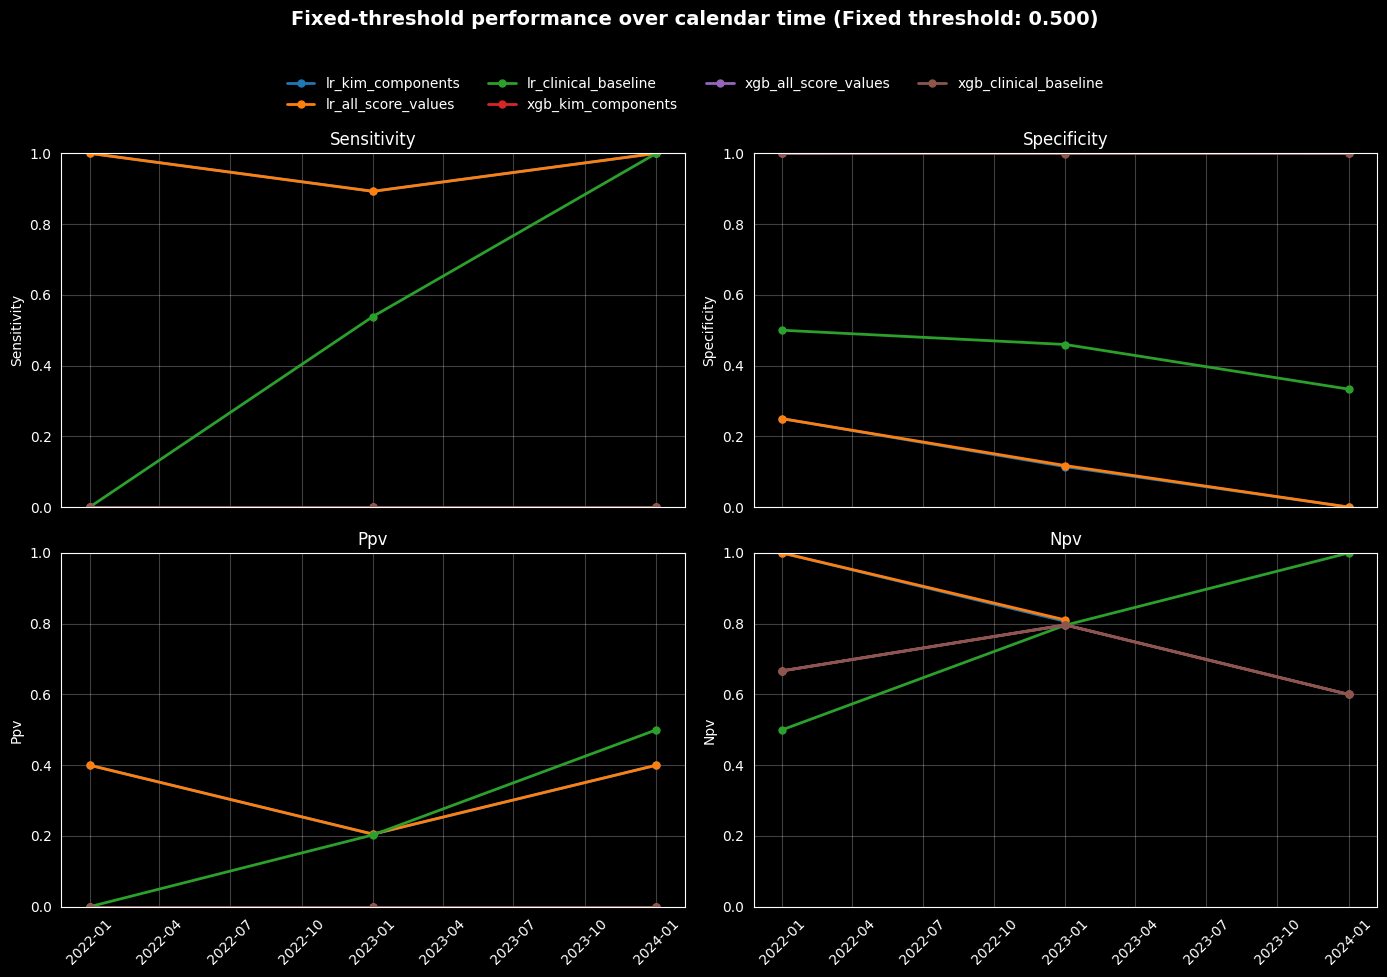

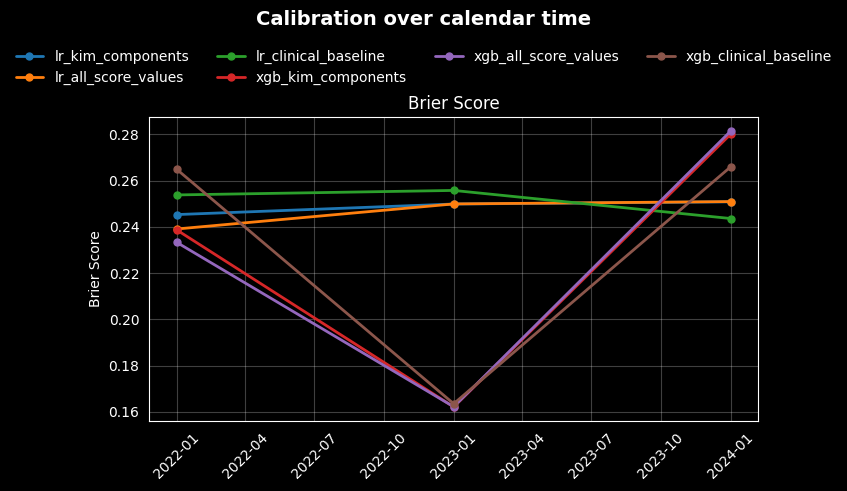

In [7]:
# Libraries
from icare_risk.evaluation.plots import (
    plot_temporal_metrics,
    plot_calibration_metrics,
    plot_threshold_metrics,
    plot_temporal_event_rate
)

if temporal_results.empty:
    print('No temporal results were produced.')
else:

    discrimination_figure = plot_temporal_metrics(
        temporal_results,
        metrics=['auroc', 'auprc'],
        title='Discrimination over calendar time',
        y_limits={'auroc': (0, 1), 'auprc': (0, 1)},
    )
    display(discrimination_figure)

    threshold_figure = plot_threshold_metrics(
        temporal_results,
        metrics=['sensitivity', 'specificity', 'ppv', 'npv'],
        title='Fixed-threshold performance over calendar time',
        threshold_label=f'{threshold:.3f}',
    )
    display(threshold_figure)

    calibration_figure = plot_calibration_metrics(
        temporal_results,
        metrics=['brier_score'], #, 'calibration_intercept', 'calibration_slope'],
        title='Calibration over calendar time',
    )
    display(calibration_figure)

In [8]:
# Libraries
from icare_risk.evaluation.plots import save_figure

# Save tables and figures.
temporal_directory = Path(config['outputs']['temporal_directory'])
temporal_directory.mkdir(parents=True, exist_ok=True)

event_rate_summary.to_csv(temporal_directory / 'temporal_event_rate_summary.csv', index=False)
split_summary.to_csv(temporal_directory / 'temporal_split_summary.csv', index=False)
temporal_results.to_csv(temporal_directory / 'temporal_performance.csv', index=False)


# Save figures
figures = [
    (event_rate_figure,     temporal_directory / 'temporal_event_rate.png'),
    (discrimination_figure, temporal_directory / 'temporal_discrimination.png'),
    (threshold_figure,      temporal_directory / 'temporal_threshold_metrics.png'),
    (calibration_figure,    temporal_directory / 'temporal_calibration.png')
]

for fig, output_path in figures:
    save_figure(fig, output_path, close=True)
    print(f'Saved figure: {output_path}')
print(f'Saved temporal tables and figures to {temporal_directory}')


Saved figure: results/temporal/temporal_event_rate.png
Saved figure: results/temporal/temporal_discrimination.png
Saved figure: results/temporal/temporal_threshold_metrics.png
Saved figure: results/temporal/temporal_calibration.png
Saved temporal tables and figures to results/temporal
